# Phase 2 — Rendements et volatilité historique

Calcul des rendements logarithmiques et des indicateurs de volatilité à partir des données préparées en phase 1.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
prices = pd.read_csv(ROOT / 'data/processed/sp500_prices.csv', parse_dates=['date'])
prices.head()

,date,close
0,2016-09-06,2186.479980
1,2016-09-07,2186.159912
2,2016-09-08,2181.300049
3,2016-09-09,2127.810059
4,2016-09-12,2159.040039


## 1. Calcul des rendements logarithmiques

Le rendement est calculé par `log(clôture courante / clôture précédente)`. La première valeur est indisponible faute de prix antérieur. Le calcul direct présenté convient à la série complète du S&P 500 ; les séries comportant une séance manquante nécessitent un alignement préalable sur leur calendrier.

In [2]:
example = prices.head(6).copy()
example['previous_close'] = example['close'].shift(1)
example['log_return'] = np.log(example['close'] / example['previous_close'])
example['log_return_percent'] = example['log_return'] * 100
example

,date,close,previous_close,log_return,log_return_percent
0,2016-09-06,2186.479980,NaN,NaN,NaN
1,2016-09-07,2186.159912,2186.479980,-0.000146,-0.014640
2,2016-09-08,2181.300049,2186.159912,-0.002225,-0.222549
3,2016-09-09,2127.810059,2181.300049,-0.024828,-2.482774
4,2016-09-12,2159.040039,2127.810059,0.014570,1.457039
5,2016-09-13,2127.020020,2159.040039,-0.014942,-1.494175


## 2. Séries calculées

Les résultats sont stockés en unités décimales. La multiplication par 100 intervient uniquement pour l’affichage en pourcentage.

In [3]:
sp = pd.read_csv(ROOT / 'data/processed/sp500_phase2.csv', index_col='date', parse_dates=True)
sp[['close', 'log_return', 'vol_21d_daily', 'vol_63d_daily']].head(25)

,close,log_return,vol_21d_daily,vol_63d_daily
date,,,,
2016-09-06,2186.479980,NaN,NaN,NaN
2016-09-07,2186.159912,-0.000146,NaN,NaN
2016-09-08,2181.300049,-0.002225,NaN,NaN
2016-09-09,2127.810059,-0.024828,NaN,NaN
2016-09-12,2159.040039,0.014570,NaN,NaN
2016-09-13,2127.020020,-0.014942,NaN,NaN
2016-09-14,2125.770020,-0.000588,NaN,NaN
2016-09-15,2147.260010,0.010059,NaN,NaN
2016-09-16,2139.159912,-0.003779,NaN,NaN


## 3. Volatilité historique

La dispersion des rendements est mesurée par l’écart-type d’échantillon avec `ddof=1`. Une valeur quotidienne de 0,01 correspond à 1 %. La mesure décrit les fluctuations observées sur la période considérée.

In [4]:
daily_vol = sp['log_return'].std(ddof=1)
print(f'Historical daily volatility: {daily_vol:.2%}')
print(f'Annualized volatility: {daily_vol * np.sqrt(252):.2%}')

Historical daily volatility: 1.14%
Annualized volatility: 18.14%


## 4. Volatilités glissantes

Les fenêtres de 21 et 63 séances se terminent à la date courante et exigent respectivement 21 et 63 rendements valides. Cette exigence conserve l’incidence des données manquantes.

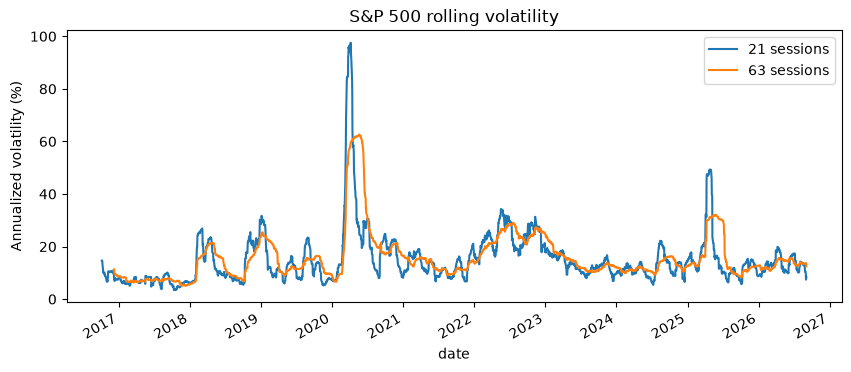

In [5]:
rolling_21 = sp['log_return'].rolling(21, min_periods=21).std(ddof=1)
np.testing.assert_allclose(rolling_21, sp['vol_21d_daily'], equal_nan=True)
ax = (sp[['vol_21d_annualized', 'vol_63d_annualized']] * 100).plot(figsize=(10, 4), title='S&P 500 rolling volatility')
ax.set_ylabel('Annualized volatility (%)')
ax.legend(['21 sessions', '63 sessions'])
plt.show()

## 5. Comparaison des statistiques descriptives

L’annualisation utilise la convention `volatilité quotidienne × sqrt(252)`. Chaque marché conserve son calendrier de séances. Les valeurs annualisées restent des mesures historiques.

In [6]:
summary = pd.read_csv(ROOT / 'reports/phase2_summary.csv')
display_table = summary[['index', 'valid_daily_returns', 'historical_daily_volatility', 'historical_annualized_volatility']].copy()
for col in ['historical_daily_volatility', 'historical_annualized_volatility']:
    display_table[col] = display_table[col].map(lambda x: f'{x:.2%}')
display_table

,index,valid_daily_returns,historical_daily_volatility,historical_annualized_volatility
0,S&P 500,2513,1.14%,18.14%
1,CAC 40,2558,1.10%,17.44%
2,FTSE 100,2523,0.93%,14.81%


## 6. Incidence de la lacune du FTSE

La clôture du 22 décembre 2020 est indisponible. Cette séance est conservée dans la table avec une valeur manquante. Son rendement et celui de la séance suivante sont indisponibles : le rapport entre les clôtures des 21 et 23 décembre couvre plusieurs séances.

In [7]:
ftse = pd.read_csv(ROOT / 'data/processed/ftse100_phase2.csv', index_col='date', parse_dates=True)
ftse.loc['2020-12-18':'2020-12-29', ['close', 'missing_price', 'log_return', 'vol_21d_daily']]

,close,missing_price,log_return,vol_21d_daily
date,,,,
2020-12-18,6529.200195,False,-0.003349,0.008178
2020-12-21,6416.299805,False,-0.017443,0.009147
2020-12-22,NaN,True,NaN,NaN
2020-12-23,6495.799805,False,NaN,NaN
2020-12-24,6502.100098,False,0.000969,NaN
2020-12-29,6602.700195,False,0.015353,NaN


## 7. Rendements et volatilités des trois marchés

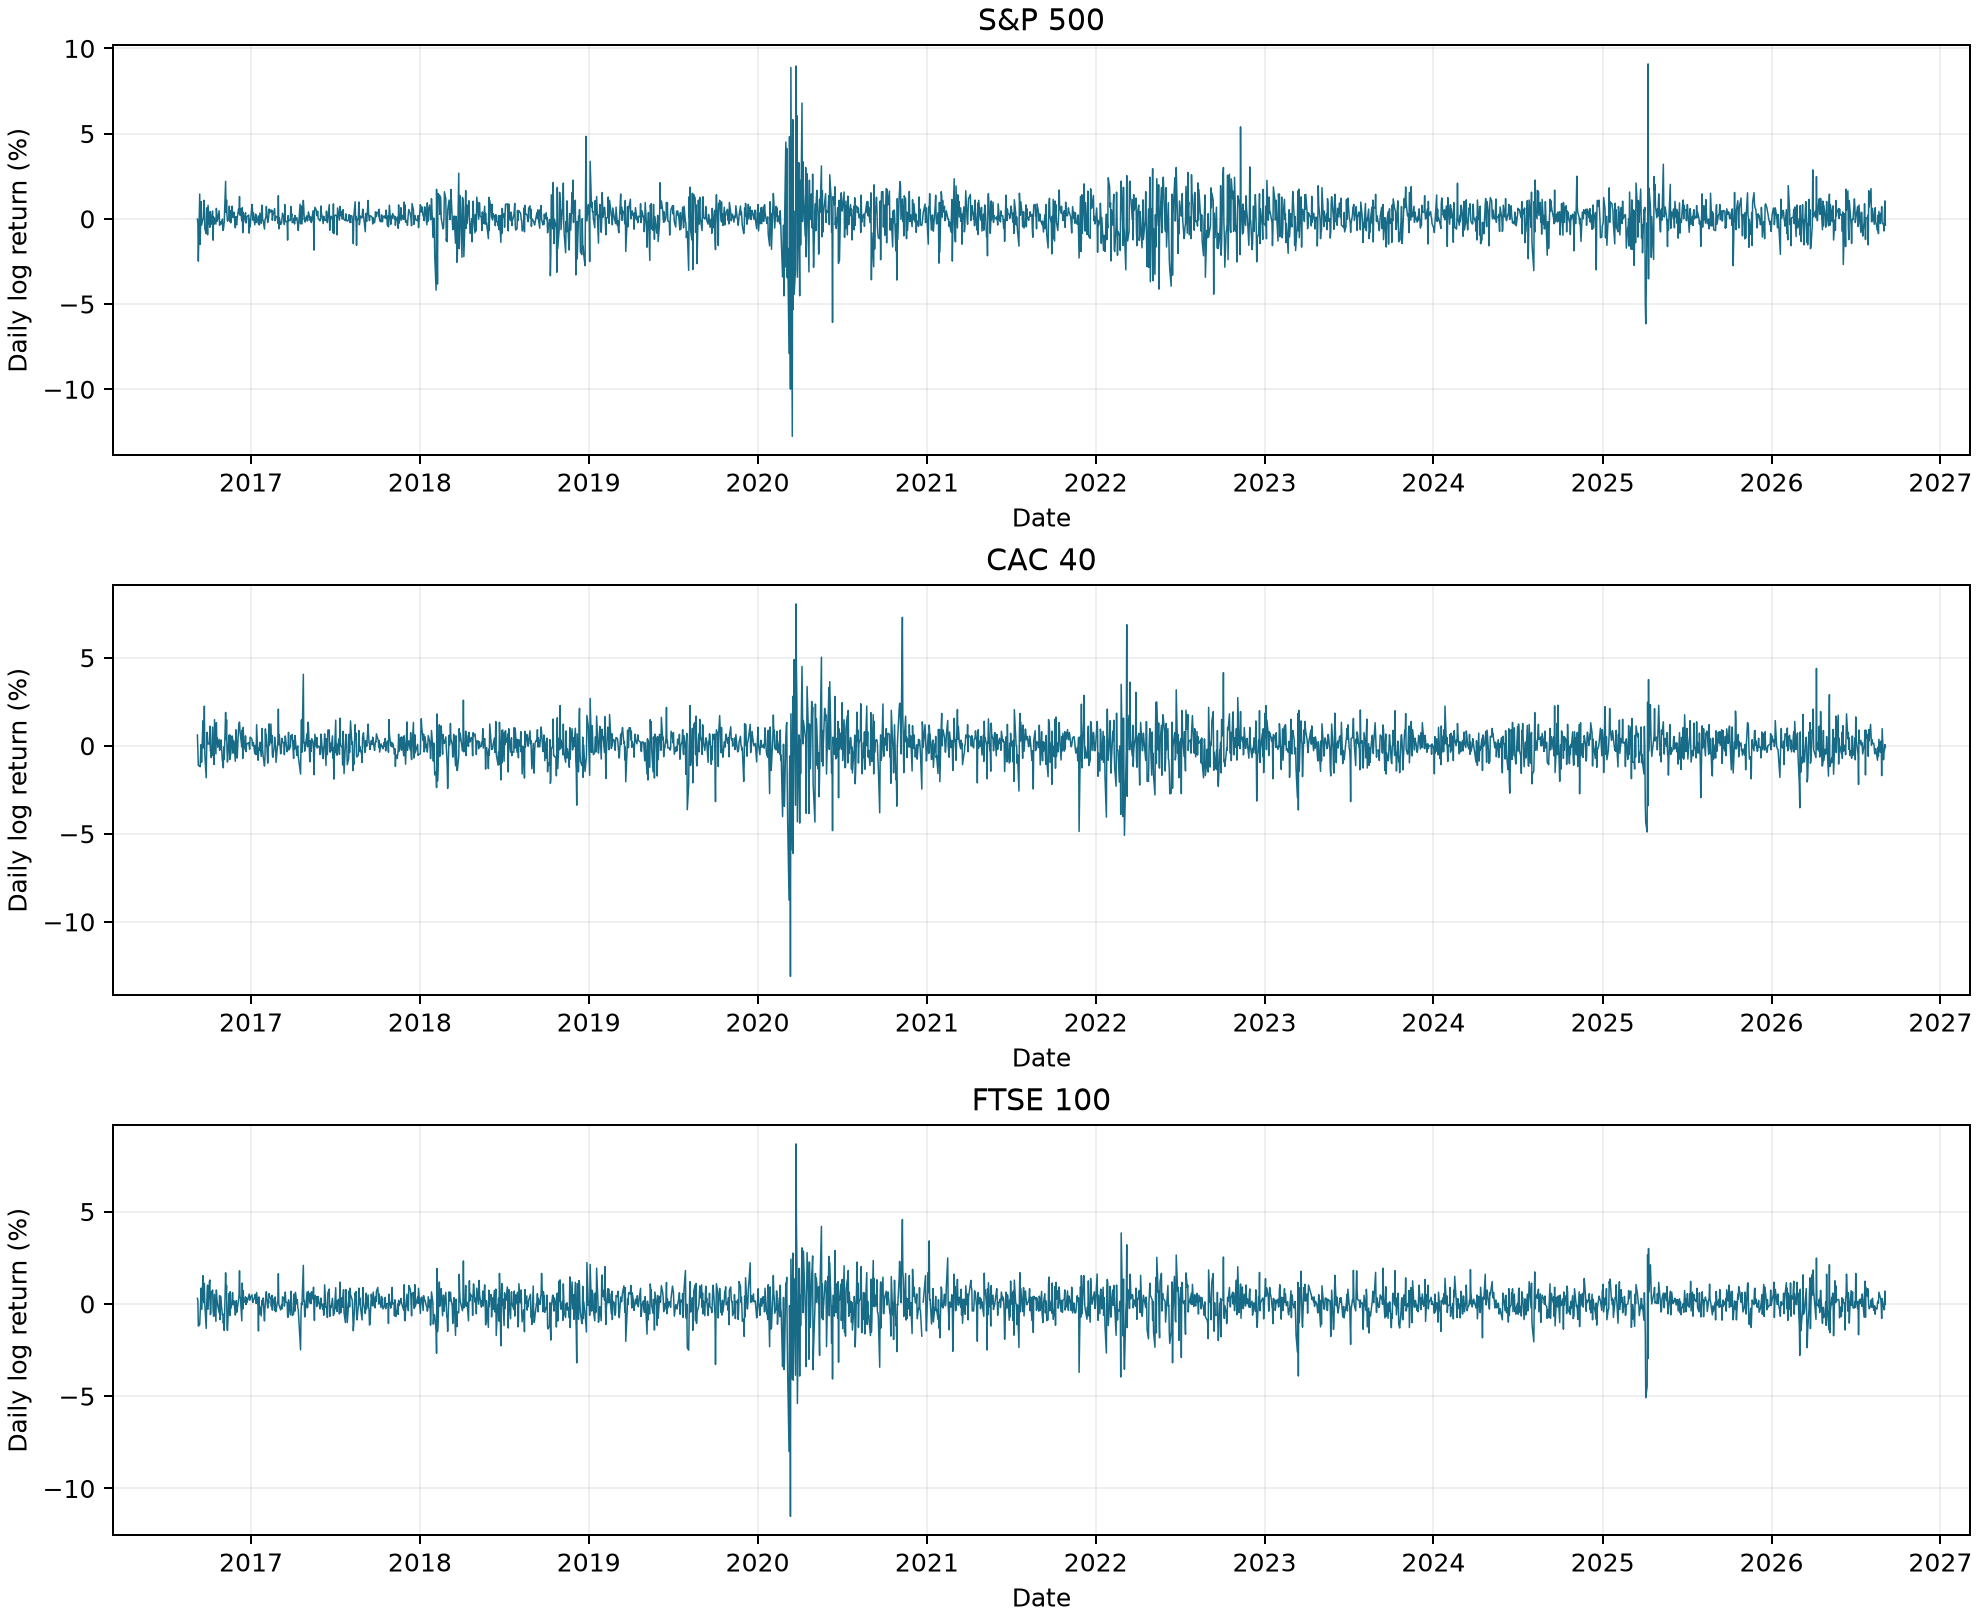

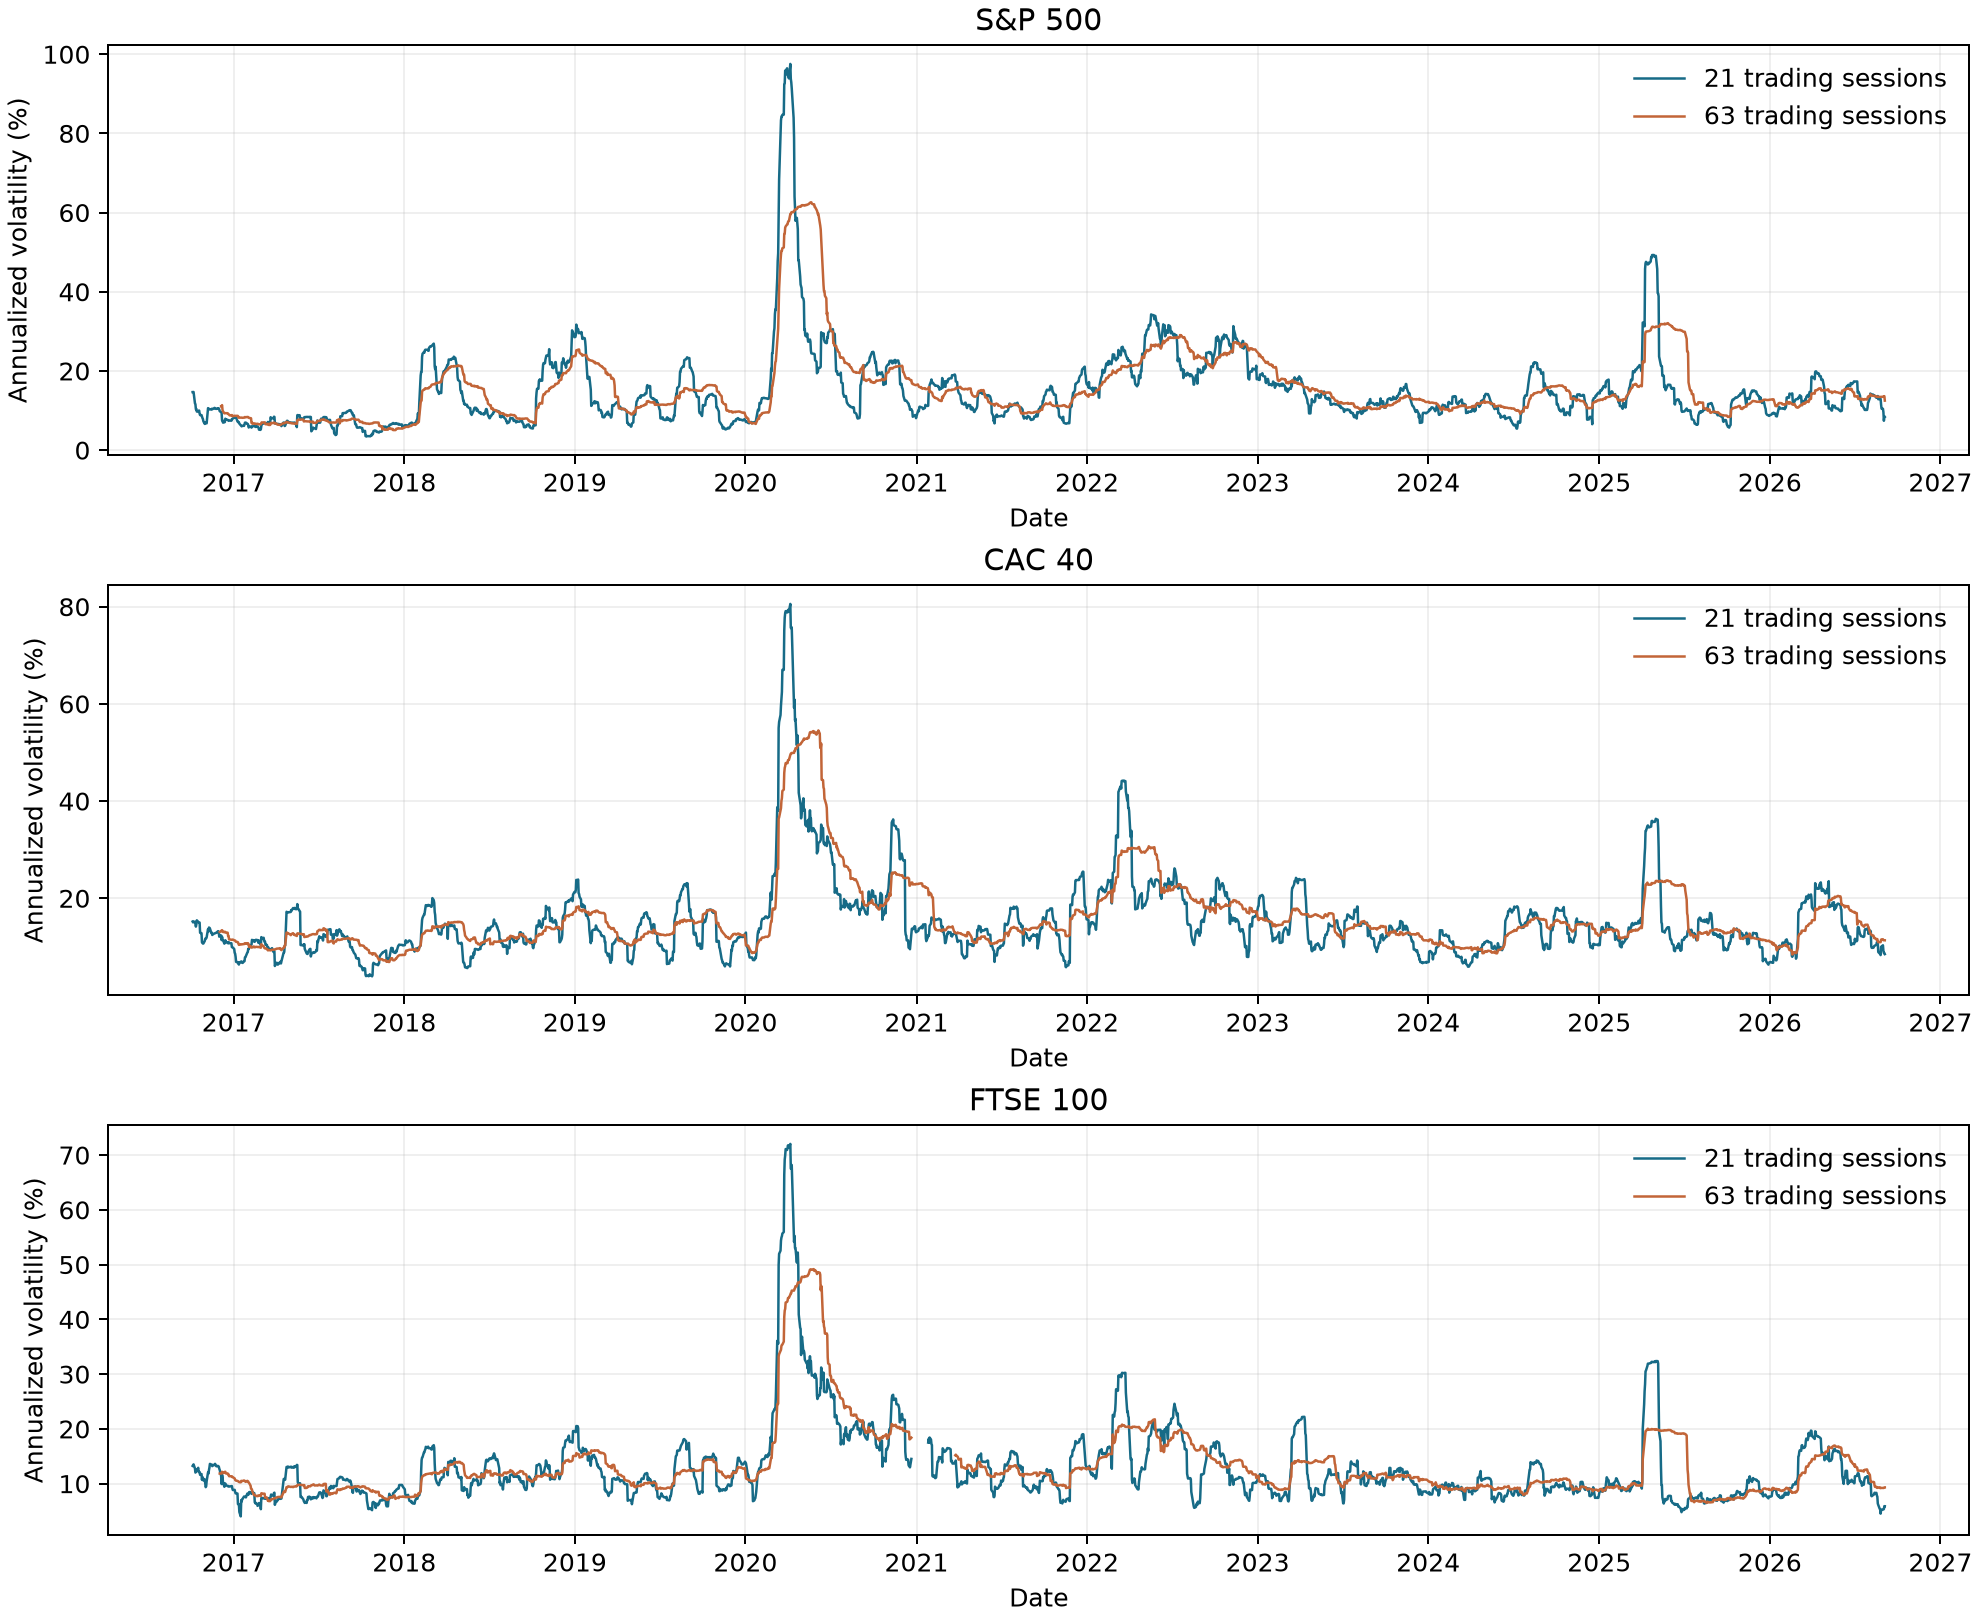

In [8]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / 'reports/figures/phase2_daily_returns.png')))
display(Image(filename=str(ROOT / 'reports/figures/phase2_rolling_volatility.png')))